In [1]:
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from huggingface_hub import login, HfApi, hf_hub_download



## Data Loading and Review



In [3]:
login()

In [4]:
api = HfApi()

user_info = api.whoami()

print("Authentication successful.")
print("Username:", user_info["name"])

Authentication successful.
Username: AbolfazlPournaderian


In [5]:
repo_id = "nexar-ai/nexar_collision_prediction"

print("Dataset repository:", repo_id)

Dataset repository: nexar-ai/nexar_collision_prediction


In [6]:
all_files = api.list_repo_files(
    repo_id=repo_id,
    repo_type="dataset"
)

print("Total files in repository:", len(all_files))

for file_path in all_files[:30]:
    print(file_path)

Total files in repository: 2857
.gitattributes
LICENSE
README.md
evaluate_submission.py
sample_submission.csv
solution.csv
test-private/negative/01047.mp4
test-private/negative/01053.mp4
test-private/negative/01055.mp4
test-private/negative/01057.mp4
test-private/negative/01063.mp4
test-private/negative/01064.mp4
test-private/negative/01077.mp4
test-private/negative/01082.mp4
test-private/negative/01086.mp4
test-private/negative/01087.mp4
test-private/negative/01091.mp4
test-private/negative/01093.mp4
test-private/negative/01104.mp4
test-private/negative/01105.mp4
test-private/negative/01106.mp4
test-private/negative/01107.mp4
test-private/negative/01120.mp4
test-private/negative/01123.mp4
test-private/negative/01124.mp4
test-private/negative/01160.mp4
test-private/negative/01161.mp4
test-private/negative/01174.mp4
test-private/negative/01183.mp4
test-private/negative/01186.mp4


In [7]:
readme_path = hf_hub_download(
    repo_id=repo_id,
    filename="README.md",
    repo_type="dataset"
)

positive_metadata_path = hf_hub_download(
    repo_id=repo_id,
    filename="train/positive/metadata.csv",
    repo_type="dataset"
)

negative_metadata_path = hf_hub_download(
    repo_id=repo_id,
    filename="train/negative/metadata.csv",
    repo_type="dataset"
)

print("Metadata files downloaded successfully.")
print("README path:", readme_path)
print("Positive metadata path:", positive_metadata_path)
print("Negative metadata path:", negative_metadata_path)

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

metadata.csv:   0%|          | 0.00/33.3k [00:00<?, ?B/s]

metadata.csv:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Metadata files downloaded successfully.
README path: /root/.cache/huggingface/hub/datasets--nexar-ai--nexar_collision_prediction/snapshots/7535d0656dac31d7da2846913bb69c6331d2a70a/README.md
Positive metadata path: /root/.cache/huggingface/hub/datasets--nexar-ai--nexar_collision_prediction/snapshots/7535d0656dac31d7da2846913bb69c6331d2a70a/train/positive/metadata.csv
Negative metadata path: /root/.cache/huggingface/hub/datasets--nexar-ai--nexar_collision_prediction/snapshots/7535d0656dac31d7da2846913bb69c6331d2a70a/train/negative/metadata.csv


In [8]:
train_positive = pd.read_csv(positive_metadata_path)
train_negative = pd.read_csv(negative_metadata_path)

print("Positive samples:", len(train_positive))
print("Negative samples:", len(train_negative))
print("Total training samples:", len(train_positive) + len(train_negative))

Positive samples: 750
Negative samples: 750
Total training samples: 1500


In [9]:
with open(readme_path, "r", encoding="utf-8") as file:
    readme_text = file.read()

print(readme_text[:12000])

---
license: other
license_name: nexar-open-data-license
license_link: LICENSE
language:
- en
pretty_name: Nexar Collision Prediction Dataset
task_categories:
- video-classification
tags:
- automotive
- dashcam
- collision
- prediction
size_categories:
- 1K<n<10K
extra_gated_heading: >-
  If you access this dataset, you consent to sharing your contact information with
  us. If you do not wish to share such data, do not access this dataset.
extra_gated_prompt: >-
  Access to this dataset is governed by the Nexar Open Data License, included in
  this repository as LICENSE. It permits free use with attribution, and prohibits
  resale, reidentification of people or vehicles, weapons development, and use in
  systems intended to cause harm. Please read it before requesting access.
extra_gated_fields:
  First Name: text
  Last Name: text
  Title: text
  Company Email: text
  Company or institution: text
  Topic of Interest:
    type: select
    options:
    - Research
    - Commercial
    - 

In [10]:
print("Positive Dataset Information:")
train_positive.info()

print("\nNegative Dataset Information:")
train_negative.info()

Positive Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   file_name         750 non-null    object 
 1   time_of_event     750 non-null    float64
 2   time_of_alert     750 non-null    float64
 3   light_conditions  750 non-null    object 
 4   weather           749 non-null    object 
 5   scene             750 non-null    object 
 6   time_to_accident  0 non-null      float64
dtypes: float64(3), object(4)
memory usage: 41.1+ KB

Negative Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   file_name         750 non-null    object 
 1   time_of_event     0 non-null      float64
 2   time_of_alert     0 non-null      float64
 3   light_condition

In [11]:
print("Missing Values in Positive Dataset:")
display(train_positive.isnull().sum().to_frame("Missing Values"))

print("\nMissing Values in Negative Dataset:")
display(train_negative.isnull().sum().to_frame("Missing Values"))

Missing Values in Positive Dataset:


,Missing Values
file_name,0
time_of_event,0
time_of_alert,0
light_conditions,0
weather,1
scene,0
time_to_accident,750



Missing Values in Negative Dataset:


,Missing Values
file_name,0
time_of_event,750
time_of_alert,750
light_conditions,0
weather,1
scene,0
time_to_accident,750


In [12]:
print("Positive Dataset Columns:")
print(train_positive.columns.tolist())

print("\nNegative Dataset Columns:")
print(train_negative.columns.tolist())

print("\nFirst Five Positive Samples:")
display(train_positive.head())

print("\nFirst Five Negative Samples:")
display(train_negative.head())

Positive Dataset Columns:
['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

Negative Dataset Columns:
['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident']

First Five Positive Samples:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,00822.mp4,19.500,18.633,Normal,Cloudy,Urban,NaN
1,00208.mp4,19.800,19.233,Normal,Cloudy,Sub-urban,NaN
2,00072.mp4,20.101,20.068,Normal,Clear,Urban,NaN
3,00128.mp4,19.267,18.333,Normal,Clear,Urban,NaN
4,00205.mp4,21.146,18.196,Normal,Clear,Highway,NaN



First Five Negative Samples:


,file_name,time_of_event,time_of_alert,light_conditions,weather,scene,time_to_accident
0,01924.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN
1,01429.mp4,NaN,NaN,Normal,Rain,Urban,NaN
2,01904.mp4,NaN,NaN,Normal,Cloudy,Urban,NaN
3,01486.mp4,NaN,NaN,Normal,Clear,Urban,NaN
4,01171.mp4,NaN,NaN,Normal,Clear,Sub-urban,NaN


In [13]:
positive_analysis = train_positive.copy()

positive_analysis["alert_lead_time"] = (
    positive_analysis["time_of_event"]
    - positive_analysis["time_of_alert"]
)

print("Alert Lead Time Statistics (seconds):")
display(positive_analysis["alert_lead_time"].describe())

Alert Lead Time Statistics (seconds):


,alert_lead_time
count,750.000000
mean,1.600357
std,0.866063
min,0.033000
25%,0.986250
50%,1.433000
75%,2.089500
max,4.466000


In [14]:
print("First Ten Alert Lead Time Records:")

display(
    positive_analysis[
        [
            "file_name",
            "time_of_event",
            "time_of_alert",
            "alert_lead_time"
        ]
    ].head(10)
)

print("Number of Missing Alert Lead Times:")
print(positive_analysis["alert_lead_time"].isna().sum())

print("Number of Non-Positive Alert Lead Times:")
print((positive_analysis["alert_lead_time"] <= 0).sum())

First Ten Alert Lead Time Records:


,file_name,time_of_event,time_of_alert,alert_lead_time
0,00822.mp4,19.500,18.633,0.867
1,00208.mp4,19.800,19.233,0.567
2,00072.mp4,20.101,20.068,0.033
3,00128.mp4,19.267,18.333,0.934
4,00205.mp4,21.146,18.196,2.950
5,00408.mp4,19.953,17.551,2.402
6,00948.mp4,20.287,19.219,1.068
7,00457.mp4,19.600,19.367,0.233
8,00471.mp4,19.833,18.267,1.566
9,00900.mp4,21.177,17.942,3.235


Number of Missing Alert Lead Times:
0
Number of Non-Positive Alert Lead Times:
0


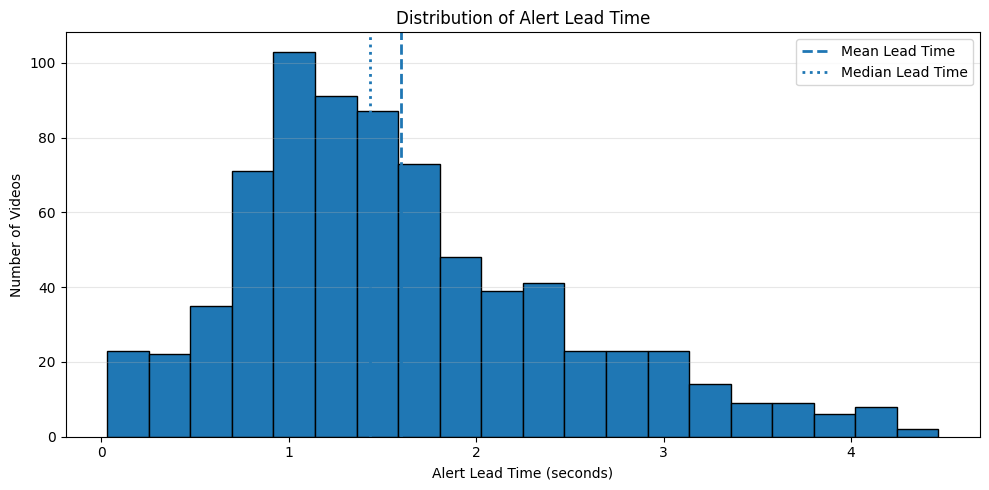

In [15]:
plt.figure(figsize=(10, 5))

plt.hist(
    positive_analysis["alert_lead_time"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.axvline(
    positive_analysis["alert_lead_time"].mean(),
    linestyle="--",
    linewidth=2,
    label="Mean Lead Time"
)

plt.axvline(
    positive_analysis["alert_lead_time"].median(),
    linestyle=":",
    linewidth=2,
    label="Median Lead Time"
)

plt.title("Distribution of Alert Lead Time")
plt.xlabel("Alert Lead Time (seconds)")
plt.ylabel("Number of Videos")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
thresholds = [1.0, 1.5, 2.0]

lead_times = positive_analysis["alert_lead_time"].dropna()

for threshold in thresholds:
    count = (lead_times >= threshold).sum()
    percentage = (count / len(lead_times)) * 100

    print(
        f"Videos with at least {threshold:.1f} seconds of lead time: "
        f"{count} ({percentage:.2f}%)"
    )

Videos with at least 1.0 seconds of lead time: 561 (74.80%)
Videos with at least 1.5 seconds of lead time: 353 (47.07%)
Videos with at least 2.0 seconds of lead time: 203 (27.07%)


In [17]:
positive_repo_paths = [
    f"train/positive/{str(file_name)}"
    for file_name in train_positive["file_name"]
    if f"train/positive/{str(file_name)}" in all_files
]

negative_repo_paths = [
    f"train/negative/{str(file_name)}"
    for file_name in train_negative["file_name"]
    if f"train/negative/{str(file_name)}" in all_files
]

print("Available positive training videos:", len(positive_repo_paths))
print("Available negative training videos:", len(negative_repo_paths))

if positive_repo_paths:
    positive_repo_path = positive_repo_paths[0]
    print("Selected positive video:", positive_repo_path)

if negative_repo_paths:
    negative_repo_path = negative_repo_paths[0]
    print("Selected negative video:", negative_repo_path)

Available positive training videos: 750
Available negative training videos: 750
Selected positive video: train/positive/00822.mp4
Selected negative video: train/negative/01924.mp4


In [18]:
if not positive_repo_paths or not negative_repo_paths:
    raise ValueError("No matching video files were found for both classes.")

positive_video_path = hf_hub_download(
    repo_id=repo_id,
    filename=positive_repo_path,
    repo_type="dataset"
)

negative_video_path = hf_hub_download(
    repo_id=repo_id,
    filename=negative_repo_path,
    repo_type="dataset"
)

print("Positive video downloaded successfully.")
print("Positive local path:", positive_video_path)

print("\nNegative video downloaded successfully.")
print("Negative local path:", negative_video_path)

train/positive/00822.mp4: reconstructing file:   0%|          |  0.00B / 17.4MB            

train/positive/00822.mp4: downloading bytes:           |  0.00B            

train/negative/01924.mp4: reconstructing file:   0%|          |  0.00B / 23.6MB            

train/negative/01924.mp4: downloading bytes:           |  0.00B            

Positive video downloaded successfully.
Positive local path: /root/.cache/huggingface/hub/datasets--nexar-ai--nexar_collision_prediction/snapshots/7535d0656dac31d7da2846913bb69c6331d2a70a/train/positive/00822.mp4

Negative video downloaded successfully.
Negative local path: /root/.cache/huggingface/hub/datasets--nexar-ai--nexar_collision_prediction/snapshots/7535d0656dac31d7da2846913bb69c6331d2a70a/train/negative/01924.mp4
